# Mini-Project — Predicting Heart Disease Using Logistic Regression

This notebook uses the course's UCI Heart Disease archive. Keep **UCI Heart Disease Data.zip** beside the notebook or upload it to the Colab working directory, then run the cells in order. The target is the dataset's recorded disease status.

In [1]:
# Step 1. Read the course CSV directly from the archive and inspect its schema.
from pathlib import Path
from zipfile import ZipFile
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

archive = Path("UCI Heart Disease Data.zip")
with ZipFile(archive) as zipped, zipped.open("heart_disease_uci.csv") as csv:
    raw = pd.read_csv(csv, na_values=["?"])

print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
raw.info()
print(raw.head().to_string(index=False))
print(raw.describe().round(2).to_string())
print("Missing values before cleaning:")
print(raw.isna().sum().sort_values(ascending=False).to_string())
print("Source rows by collection site:")
print(raw["dataset"].value_counts().to_string())

# Step 2. Make the binary target: 0 = absence, 1–4 = presence.
# Drop identifiers and collection site so the model uses clinical features.
assert raw["num"].isin([0, 1, 2, 3, 4]).all()
data = raw.drop(columns=["id", "dataset"]).copy()
data["disease"] = data.pop("num").gt(0).astype(int)

# Zero values for these measurements are treated as missing placeholders.
# Keep valid zeros in fields such as oldpeak and the vessel count.
for column in ["trestbps", "chol", "thalch"]:
    zero = data[column].eq(0)
    print(f"Zero {column} values recoded as missing: {zero.sum()}")
    data.loc[zero, column] = float("nan")

# Normalize Boolean categories to text while preserving missing values.
for column in ["fbs", "exang"]:
    data[column] = data[column].map({True: "Yes", False: "No", "True": "Yes", "False": "No"})

# Drop exact repeats of the modeling record, including its target.
# Otherwise identical labeled records could appear in both splits.
duplicates = data.duplicated().sum()
data = data.drop_duplicates()
print(f"Repeated modeling records removed: {duplicates}")
print(data["disease"].value_counts().sort_index().rename(index={0: "Absent", 1: "Present"}))

Rows: 920 | Columns: 16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
 id  age    sex   dataset              cp  trestbps  chol   fbs        restecg  thalch exang  oldpeak    

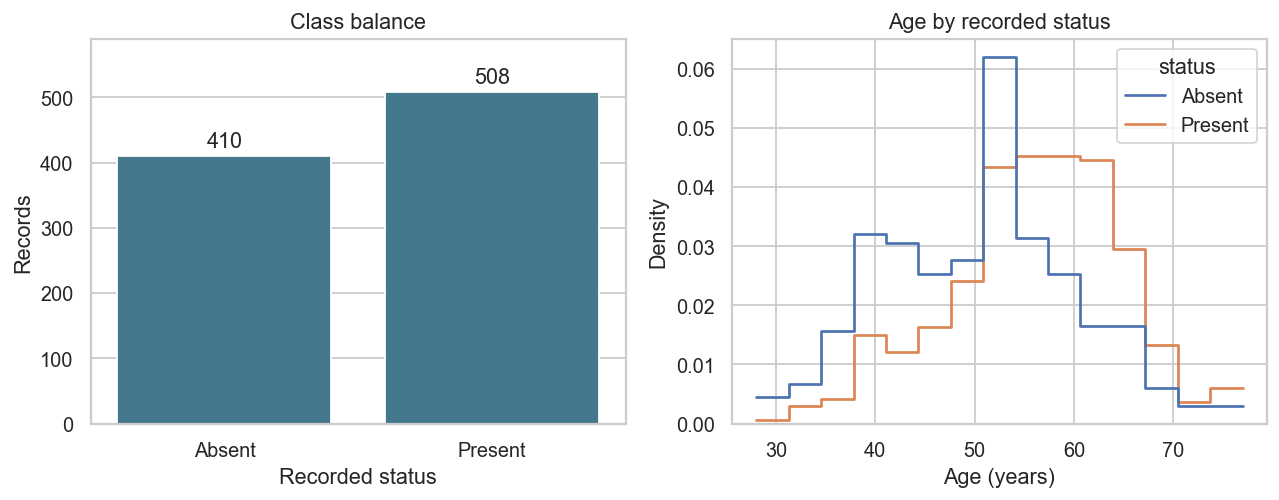

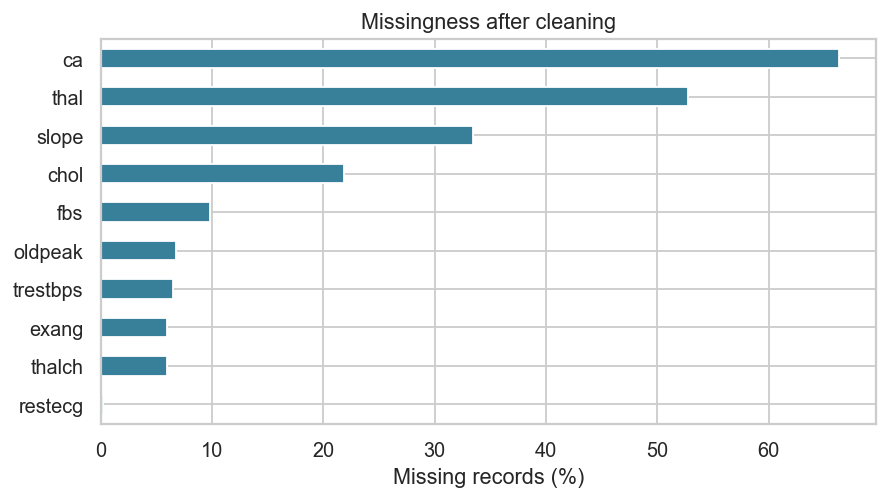

In [2]:
# Step 3. Plot class balance, age distributions, and the missing-data pattern.
sns.set_theme(style="whitegrid")
labels = data["disease"].map({0: "Absent", 1: "Present"})
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=labels, order=["Absent", "Present"], color="#387f99", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set(xlabel="Recorded status", ylabel="Records", title="Class balance")
axes[0].set_ylim(0, labels.value_counts().max() * 1.16)
sns.histplot(data=data.assign(status=labels), x="age", hue="status",
             hue_order=["Absent", "Present"], element="step", fill=False,
             common_norm=False, stat="density", bins=15, ax=axes[1])
axes[1].set(xlabel="Age (years)", title="Age by recorded status")
fig.tight_layout()
plt.show()

missing = data.isna().mean().mul(100).loc[lambda rates: rates.gt(0)].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
missing.plot.barh(color="#387f99", ax=ax)
ax.set(xlabel="Missing records (%)", title="Missingness after cleaning")
fig.tight_layout()
plt.show()

In [3]:
# Step 4. Keep 20% of the data aside. Stratification preserves class balance.
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = data.drop(columns="disease")
y = data["disease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training: {len(y_train)} | Test: {len(y_test)}")

# Step 5. Median-fill numeric inputs and standardize their scales. Fill
# missing categorical values with a separate label, then one-hot encode.
# The pipeline fits all preprocessing on the training rows only.
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
numeric = [column for column in X if column not in categorical]
preprocess = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              StandardScaler()), numeric),
    ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="Missing"),
                                  OneHotEncoder(handle_unknown="ignore")), categorical),
])

# Step 6. Fit logistic regression and a majority-class reference model.
model = make_pipeline(preprocess, LogisticRegression(max_iter=2000))
model.fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

Training: 734 | Test: 184


Accuracy                  86.41%
Precision                 85.98%
Recall                    90.20%
F1                        88.04%
Majority-class accuracy   55.43%
              precision    recall  f1-score   support

      Absent      0.870     0.817     0.843        82
     Present      0.860     0.902     0.880       102

    accuracy                          0.864       184
   macro avg      0.865     0.860     0.862       184
weighted avg      0.864     0.864     0.864       184

True negatives: 67 | False positives: 15 | False negatives: 10 | True positives: 92


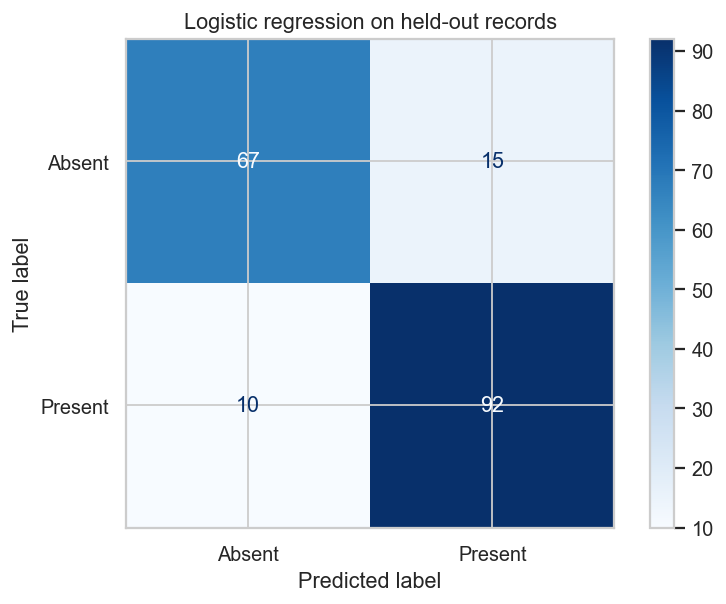

In [4]:
# Step 7. Predict the held-out labels and calculate the requested metrics.
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)

predicted = model.predict(X_test)
scores = pd.Series({
    "Accuracy": accuracy_score(y_test, predicted),
    "Precision": precision_score(y_test, predicted, zero_division=0),
    "Recall": recall_score(y_test, predicted, zero_division=0),
    "F1": f1_score(y_test, predicted, zero_division=0),
    "Majority-class accuracy": baseline.score(X_test, y_test),
})
print(scores.to_string(float_format=lambda score: f"{score:.2%}"))
print(classification_report(y_test, predicted, labels=[0, 1],
                            target_names=["Absent", "Present"], digits=3, zero_division=0))

# Step 8. Read actual labels down the rows and predictions across columns.
matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
ConfusionMatrixDisplay(matrix, display_labels=["Absent", "Present"]).plot(cmap="Blues")
plt.title("Logistic regression on held-out records")
plt.tight_layout()
plt.show()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")

## Interpretation

The model achieved **86.41% accuracy**, compared with **55.43%** for the majority-class baseline. It detected **90.20%** of records labeled with disease, missing **10**. Among positive predictions, **85.98%** matched the recorded label. The positive-class F1 score was **0.880**.

Missingness varies across features, especially for the vessel count and thal category. A random split estimates performance on similar records from the same mix of sources. Testing on an entire unseen collection site would answer a different question about transfer to a new site.